# Notebook 12 — Chẩn đoán hội tụ QAOA

Notebook này phân biệt **nhiễu shots**, **điểm khởi tạo** và **lý do optimizer dừng**. Giữ mô hình task placement của Phase 1/2: mỗi task nằm nguyên vẹn trên đúng một host; không sửa bit hoặc slack sau khi đo.

Mỗi instance có **8 lượt**: 6 lượt tối ưu bằng shots (2 khởi tạo × 3 seed) và 2 lượt tối ưu bằng kỳ vọng chính xác (mỗi khởi tạo một lượt). Đối chứng chính xác dùng mô phỏng lý tưởng; kết quả placement của cả hai cách vẫn chấm từ **1024 shots cuối bằng seed riêng**. Đây là chẩn đoán có giới hạn, chưa phải một cấu hình bảo đảm tối ưu.

Chạy `p1_choice` trước. Lưu bản có output, restart kernel rồi đổi sang `p0_reference`. Hướng dẫn đầy đủ: `docs/qaoa_convergence_diagnostics.md`.

## Bước 1 — Kiểm tra kernel và nhập module

Chọn kernel Conda `nt409-khiem` trong VS Code. Python 3.12 trong kernel là môi trường đã dùng cho dự án; Python 3.14 cài toàn hệ thống không quyết định kernel này. Restart kernel sau khi cập nhật các file `src/` để Python nạp mã mới.

In [1]:
from pathlib import Path
import sys
import json
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import psutil
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "qubo.py").is_file():
    ROOT = ROOT.parent
if not (ROOT / "src" / "qubo.py").is_file():
    raise RuntimeError("Mở notebook từ thư mục dự án nt409-task-placement.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.qubo import build_qubo
from src.qaoa_experiment import (prepare_reference, probe_qaoa_resources,
    run_qaoa_experiment, experiment_environment, _MemoryMonitor)
from src.convergence_diagnostics import ExactQAOAOracle, run_exact_qaoa
from src.convergence_campaign import (make_design, make_trials, new_campaign,
    save_campaign, verify_campaign, record_trial)

if tuple(int(x) for x in scipy.__version__.split(".")[:2]) < (1, 16):
    raise RuntimeError("Notebook 12 cần SciPy >= 1.16; xem requirements.txt.")
print("ROOT:", ROOT)
print("Python:", sys.executable)
print(json.dumps(experiment_environment()["runtime"], indent=2))
print(f"RAM khả dụng: {psutil.virtual_memory().available / 2**30:.2f} GiB")

ROOT: C:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement
Python: c:\Users\Khiem\anaconda3\envs\nt409-khiem\python.exe
{
  "python_version": "3.12.14",
  "platform": "Windows-11-10.0.26200-SP0",
  "numpy_version": "2.5.3",
  "scipy_version": "1.18.1",
  "qiskit_version": "2.5.2",
  "qiskit_optimization_version": "0.7.0",
  "qiskit_aer_version": "0.17.2"
}
RAM khả dụng: 13.85 GiB


## Bước 2 — Chốt cấu hình trước khi xem kết quả

Chỉ đổi `INSTANCE_ID` khi chuyển input. Giữ nguyên hai khởi tạo, seed và ngân sách để đối chiếu. `maxiter=80` là giới hạn số lần đánh giá hàm, không phải yêu cầu optimizer phải chạy đủ 80 lần.

`RESUME_MANIFEST=None` tạo đợt mới. Muốn tiếp tục một đợt notebook 12 bị ngắt, điền đường dẫn manifest đã in ở Bước 5; giữ nguyên input/cấu hình/mã/phiên bản môi trường. Manifest của notebook 11 không dùng ở đây.

In [2]:
INSTANCE_ID = "p1_choice"  # Lượt tiếp theo đổi thành "p0_reference"
RESUME_MANIFEST = None     # Ví dụ: "data/reference_results/phase4e_convergence_runs/convergence_p1_choice_....json"
SEEDS = [60, 61, 62]
STARTS = {"common": [0.3, 1.0], "alternative": [0.8, 1.2]}
BASE_CONFIG = dict(
    shots=1024, evaluation_shots=1024,
    maxiter=80, max_seconds=600., max_qubits=23,
    aer_threads=4, aer_memory_mb=2048, min_available_gib=2.,
    hamiltonian_scaling="max_abs", cobyla_rhobeg=1., cobyla_tol=1e-4,
)
assert INSTANCE_ID in ("p1_choice", "p0_reference")
print("Input:", INSTANCE_ID)
print("Hai khởi tạo [beta, gamma_execution]:", STARTS)
print("Ngân sách mỗi lượt:", BASE_CONFIG)

Input: p1_choice
Hai khởi tạo [beta, gamma_execution]: {'common': [0.3, 1.0], 'alternative': [0.8, 1.2]}
Ngân sách mỗi lượt: {'shots': 1024, 'evaluation_shots': 1024, 'maxiter': 80, 'max_seconds': 600.0, 'max_qubits': 23, 'aer_threads': 4, 'aer_memory_mb': 2048, 'min_available_gib': 2.0, 'hamiltonian_scaling': 'max_abs', 'cobyla_rhobeg': 1.0, 'cobyla_tol': 0.0001}


## Bước 3 — Dùng lại input và mô hình đã kiểm chứng

Không tạo instance mới. Cả hai penalty bằng 3; chỉ chia Hamiltonian thực thi cho hệ số `kappa`. Mọi bảng năng lượng trả về đơn vị QUBO gốc. Nghiệm placement tối ưu chỉ xét x/y; ground state còn yêu cầu đúng toàn bộ slack.

Ma trận ghi rõ **6 sampled + 2 exact**, không chạy lại đối chứng exact bằng ba seed rồi tính đó là ba quá trình tối ưu độc lập.

In [3]:
instance = json.loads((ROOT / "data" / "instances" / f"{INSTANCE_ID}.json").read_text(encoding="utf-8"))
bundle = build_qubo(instance, assignment_penalty=3, capacity_penalty=3)
reference = prepare_reference(bundle)
design = make_design(instance, bundle, SEEDS, BASE_CONFIG, STARTS)
trials = make_trials(design)
print("Qubit:", bundle["qubo"].get_num_vars(), "| x/y:", bundle["base_count"])
print("Số host tối ưu:", reference["original_best_objective"])
print("Năng lượng QUBO nhỏ nhất:", reference["minimum_energy"])
print("kappa:", design["normalization"]["scale"])
print("Uniform P_opt:", reference["uniform_baseline"]["optimal_placement_probability"])
display(pd.DataFrame([dict(arm=t["arm_id"], seed=t["seed"],
    final_seed=t["config"]["evaluation_seed"], start=t["config"]["initial_point"],
    max_evaluations=t["config"]["maxiter"], final_shots=t["config"]["evaluation_shots"])
    for t in trials]))
assert len(trials) == 8 and len({t["run_key"] for t in trials}) == 8

Qubit: 20 | x/y: 10
Số host tối ưu: 1
Năng lượng QUBO nhỏ nhất: 1.0
kappa: 74.5
Uniform P_opt: 0.0009765625


,arm,seed,final_seed,start,max_evaluations,final_shots
0,sampled_common,60,100060,"[0.3, 1.0]",80,1024
1,sampled_common,61,100061,"[0.3, 1.0]",80,1024
2,sampled_common,62,100062,"[0.3, 1.0]",80,1024
3,exact_common,60,100060,"[0.3, 1.0]",80,1024
4,sampled_alternative,60,100060,"[0.8, 1.2]",80,1024
5,sampled_alternative,61,100061,"[0.8, 1.2]",80,1024
6,sampled_alternative,62,100062,"[0.8, 1.2]",80,1024
7,exact_alternative,60,100060,"[0.8, 1.2]",80,1024


## Bước 4 — Đo thử thời gian và RAM

Đối chứng exact lưu vector năng lượng và xác suất số; không tạo ma trận Hamiltonian kích thước `2^N × 2^N`, không tạo chuỗi cho mọi bitstring. Aer chỉ chạy tuần tự trên CPU.

Ước lượng thời gian là tham khảo, gồm một hệ số dự phòng 1,5. Nếu vượt giới hạn, cell dừng **trước đợt tối ưu**. Kiểm tra RAM khả dụng và đọc hướng dẫn trước khi chỉnh ngân sách; không chạy nhiều kernel song song. Phép đo RSS đỉnh bao gồm hoạt động trước đó của kernel.

In [4]:
probe_config = trials[0]["config"]
sampled_probe = probe_qaoa_resources(bundle, probe_config)
with _MemoryMonitor() as exact_memory:
    oracle = ExactQAOAOracle(bundle, probe_config, reference)
    exact_initial = oracle.evaluate(STARTS["common"])
exact_probe = dict(setup_seconds=oracle.setup_seconds,
    evaluation_seconds=exact_initial["simulation_seconds"], resources=exact_memory.as_dict(),
    energy_vector_mib=oracle.energies.nbytes / 2**20,
    statevector_array_mib=16 * 2**bundle["qubo"].get_num_vars() / 2**20)
assert np.isclose(oracle.energies.mean(), reference["uniform_baseline"]["mean_qubo_energy"], atol=1e-7, rtol=0)
display(pd.DataFrame([
    dict(method="sampled", setup_seconds=sampled_probe["setup_seconds"],
         one_evaluation_seconds=sampled_probe["sampling_seconds"],
         peak_rss_mib=sampled_probe["resources"]["process_peak_rss_mib"]),
    dict(method="exact", setup_seconds=exact_probe["setup_seconds"],
         one_evaluation_seconds=exact_probe["evaluation_seconds"],
         peak_rss_mib=exact_probe["resources"]["process_peak_rss_mib"]),
]))
rough_sampled = 1.5 * sampled_probe["sampling_seconds"] * (BASE_CONFIG["maxiter"] + 2)
rough_exact = 1.5 * (exact_probe["evaluation_seconds"] * BASE_CONFIG["maxiter"] + sampled_probe["sampling_seconds"])
print(f"Ước lượng có dự phòng mỗi lượt sampled/exact: {rough_sampled:.1f}s / {rough_exact:.1f}s")
print(f"Ước lượng 8 lượt, chưa gồm toàn bộ hậu xử lý/audit: {6*rough_sampled+2*rough_exact:.1f}s")
print(f"RAM khả dụng sau setup: {psutil.virtual_memory().available / 2**30:.2f} GiB")
if max(rough_sampled, rough_exact) > BASE_CONFIG["max_seconds"]:
    raise RuntimeError("Ước lượng vượt max_seconds. Đọc phần tài nguyên trong hướng dẫn trước khi tạo campaign.")

,method,setup_seconds,one_evaluation_seconds,peak_rss_mib
0,sampled,0.088146,0.059180,209.859375
1,exact,0.122533,0.050844,236.128906


Ước lượng có dự phòng mỗi lượt sampled/exact: 7.3s / 6.2s
Ước lượng 8 lượt, chưa gồm toàn bộ hậu xử lý/audit: 56.1s
RAM khả dụng sau setup: 13.58 GiB


## Bước 5 — Tạo hoặc xác minh manifest notebook 12

Manifest là chỉ mục nối mỗi lượt với report nguồn và cấu hình. Chạy lại từ Bước 1 rồi điền manifest giúp tiếp tục những lượt còn thiếu; không gộp đợt cũ có seed cuối dùng lại với đợt mới.

In [5]:
RESULT_DIR = ROOT / "data" / "reference_results" / "phase4e_convergence_runs"
if RESUME_MANIFEST is None:
    campaign = new_campaign(design)
    campaign["resource_probes"] = {"sampled": sampled_probe, "exact": exact_probe}
    MANIFEST_PATH = RESULT_DIR / f"convergence_{INSTANCE_ID}_{campaign['campaign_id']}.json"
    save_campaign(MANIFEST_PATH, campaign)
else:
    MANIFEST_PATH = (ROOT / RESUME_MANIFEST).resolve()
    if not MANIFEST_PATH.is_relative_to(ROOT):
        raise ValueError("Manifest phải nằm trong thư mục dự án.")
    campaign = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
verify_campaign(ROOT, campaign, design, bundle, reference)
print("MANIFEST:", MANIFEST_PATH.relative_to(ROOT).as_posix())
print("Đã hoàn tất:", campaign["completed_run_count"], "/", campaign["planned_run_count"])
print("Còn lại:", len(campaign["remaining_run_keys"]))

MANIFEST: data/reference_results/phase4e_convergence_runs/convergence_p1_choice_20261008T034113505740Z.json
Đã hoàn tất: 0 / 8
Còn lại: 8


## Bước 6 — Chạy tuần tự 8 lượt và lưu ngay từng lượt hoàn tất

Sampled dùng shots để quyết định góc tiếp theo; exact dùng kỳ vọng lý tưởng. Hai cách dùng cùng COBYLA, khởi tạo, penalty, độ sâu, ngưỡng dừng và giới hạn 80 lần đánh giá. Chi phí mỗi đánh giá có thể khác, nên đo thời gian riêng.

Chỉ report hoàn tất mới được lưu. **Lượt hoàn tất có 0 nghiệm vẫn được lưu** vì đó là kết quả thực nghiệm. Không lưu report timeout; nếu ngắt kernel, manifest vẫn giữ các lượt đã hoàn tất. Giữ cell này chạy đến khi in `8/8` và `Còn lại: 0`.

In [6]:
current_instance = json.loads((ROOT / "data" / "instances" / f"{INSTANCE_ID}.json").read_text(encoding="utf-8"))
current_design = make_design(current_instance, bundle, SEEDS, BASE_CONFIG, STARTS)
verify_campaign(ROOT, campaign, current_design, bundle, reference)
completed = {row["run_key"] for row in campaign["completed_runs"]}
for trial in campaign["planned_runs"]:
    if trial["run_key"] in completed:
        continue
    print(f"\n{trial['arm_id']} | seed={trial['seed']} | final_seed={trial['config']['evaluation_seed']}", flush=True)
    if trial["objective_mode"] == "exact":
        report = run_exact_qaoa(bundle, trial["config"], reference, oracle, progress=True)
    else:
        report = run_qaoa_experiment(bundle, trial["config"], reference, progress=True)
    if report["status"] != "completed":
        raise RuntimeError("Lượt chưa hoàn tất; không lưu report này. Các lượt đã hoàn tất vẫn có trong manifest.")
    path = record_trial(ROOT, campaign, trial, report, bundle, oracle)
    save_campaign(MANIFEST_PATH, campaign)
    completed.add(trial["run_key"])
    print("Đã lưu:", path.name, "| stop:", report["optimizer_stop"], flush=True)

print(f"\nHoàn tất {campaign['completed_run_count']}/{campaign['planned_run_count']}")
print("Còn lại:", len(campaign["remaining_run_keys"]))


sampled_common | seed=60 | final_seed=100060
  evaluation 1: mean E=332.354492, elapsed=0.1s
  evaluation 5: mean E=272.278320, elapsed=0.4s
  evaluation 10: mean E=72.179688, elapsed=0.7s
  evaluation 15: mean E=69.942383, elapsed=1.1s
  evaluation 20: mean E=72.537109, elapsed=1.4s
  evaluation 25: mean E=69.492187, elapsed=1.8s
  evaluation 30: mean E=73.278320, elapsed=2.1s
Đã lưu: p1_choice_sampled_common_seed60_20261008T034240991372Z.json | stop: {'status': 0, 'success': True, 'message': 'Return from COBYLA because the trust region radius reaches its lower bound.', 'nfev': 32}

sampled_common | seed=61 | final_seed=100061
  evaluation 1: mean E=347.106445, elapsed=0.1s
  evaluation 5: mean E=234.009766, elapsed=0.4s
  evaluation 10: mean E=83.503906, elapsed=0.7s
  evaluation 15: mean E=73.127930, elapsed=1.0s
  evaluation 20: mean E=73.648438, elapsed=1.4s
  evaluation 25: mean E=73.139648, elapsed=1.7s
  evaluation 30: mean E=72.900391, elapsed=2.0s
Đã lưu: p1_choice_sampled_c

## Bước 7 — So ba cách đọc năng lượng tại cùng bộ góc cuối

- `E_train`: giá trị optimizer đã dùng để chọn bộ góc; sampled có nhiễu và có thể bị thiên lệch chọn điểm.
- `E_eval`: trung bình từ batch cuối bằng seed riêng; dùng để chấm kết quả placement.
- `E_exact`: kỳ vọng của phân phối lý tưởng tại đúng bộ góc đó; dùng chẩn đoán.

`SE_eval` ở đây tính từ độ lệch chuẩn năng lượng lý tưởng chia căn số shots cuối. Nó mô tả dao động của trung bình tại một điểm cố định, không chứng minh hội tụ hay tạo khoảng tin cậy sau lựa chọn cấu hình. `optimizer_success` chỉ là trạng thái dừng số học.

In [7]:
rows = verify_campaign(ROOT, campaign, design, bundle, reference)
df = pd.DataFrame(rows)
energy_table = df[["arm_id", "seed", "cost_function_evals", "optimizer_success", "optimizer_status",
    "optimizer_estimated_energy", "final_sample_mean_qubo_energy", "exact_mean_qubo_energy",
    "training_minus_exact_energy", "evaluation_minus_exact_energy", "evaluation_standard_error_exact"]].rename(
    columns={"optimizer_estimated_energy":"E_train", "final_sample_mean_qubo_energy":"E_eval",
             "exact_mean_qubo_energy":"E_exact", "evaluation_standard_error_exact":"SE_eval"})
display(energy_table.round(6))
display(df[["arm_id", "seed", "optimizer_message", "optimization_seconds", "evaluation_sampling_seconds", "exact_audit_seconds"]])

,arm_id,seed,cost_function_evals,optimizer_success,optimizer_status,E_train,E_eval,E_exact,training_minus_exact_energy,evaluation_minus_exact_energy,SE_eval
0,sampled_common,60,32,True,0,69.063477,68.064453,70.807818,-1.744341,-2.743365,2.139827
1,sampled_common,61,33,True,0,70.294922,74.315430,73.445841,-3.150919,0.869589,2.240543
2,sampled_common,62,41,True,0,67.199219,75.412109,72.498860,-5.299642,2.913249,2.218985
3,exact_common,60,80,False,3,62.289841,61.062500,62.289841,0.000000,-1.227341,1.671736
4,sampled_alternative,60,28,True,0,61.927734,65.845703,65.126314,-3.198579,0.719390,1.799881
5,sampled_alternative,61,29,True,0,72.794922,79.706055,78.231261,-5.436340,1.474793,2.444603
6,sampled_alternative,62,26,True,0,60.398438,64.500000,64.674861,-4.276423,-0.174861,1.773899
7,exact_alternative,60,80,False,3,59.319691,61.048828,59.319691,0.000000,1.729137,1.539032


,arm_id,seed,optimizer_message,optimization_seconds,evaluation_sampling_seconds,exact_audit_seconds
0,sampled_common,60,Return from COBYLA because the trust region ra...,2.291645,0.060150,0.061661
1,sampled_common,61,Return from COBYLA because the trust region ra...,2.253812,0.060548,0.058457
2,sampled_common,62,Return from COBYLA because the trust region ra...,2.895825,0.060835,0.053917
3,exact_common,60,Return from COBYLA because the objective funct...,4.547728,0.068079,0.000012
4,sampled_alternative,60,Return from COBYLA because the trust region ra...,3.847437,0.122603,0.098120
5,sampled_alternative,61,Return from COBYLA because the trust region ra...,3.730039,0.101871,0.105282
6,sampled_alternative,62,Return from COBYLA because the trust region ra...,3.499120,0.122005,0.048757
7,exact_alternative,60,Return from COBYLA because the objective funct...,4.430624,0.061283,0.000036


## Bước 8 — Chấm chất lượng placement và so theo khởi tạo

Năng lượng giảm chưa đủ: cần xem task có được gán đúng, placement khả thi/tối ưu và số lượt tìm thấy nghiệm. Xác suất tối ưu lý tưởng khác tần suất tối ưu trong 1024 shots. Ground state còn yêu cầu đúng slack.

Mỗi nhóm sampled có 3 lượt; mỗi nhóm exact có 1 lượt tối ưu. Bảng ghi `n_runs` rõ ràng. So ghép exact–sampled chỉ dùng seed 60 ở mỗi khởi tạo; không gọi đây là xác nhận thống kê hay gộp với notebook 11.

In [8]:
quality = df[["arm_id", "seed", "found_valid", "found_optimal", "observed_best_objective", "optimality_gap",
    "one_hot_probability", "feasible_probability", "optimal_placement_probability", "exact_optimal_probability",
    "qubo_ground_state_probability", "dominant_bitstring_count", "unique_mode_valid"]].copy()
quality["optimal_shots"] = (df["optimal_placement_probability"] * df["evaluation_shots"]).round().astype(int)
for col in ("one_hot_probability", "feasible_probability", "optimal_placement_probability",
            "exact_optimal_probability", "qubo_ground_state_probability"):
    quality[col] *= 100
display(quality.round(6))
print("Các cột probability trong bảng trên là %. None ở unique_mode_valid nghĩa là đồng hạng.")

summary = df.groupby(["initial_point_id", "objective_mode"], sort=False).agg(
    n_runs=("run_key", "count"), successful_trials=("found_optimal", "sum"),
    mean_exact_energy=("exact_mean_qubo_energy", "mean"),
    mean_final_energy=("final_sample_mean_qubo_energy", "mean"),
    mean_optimal_probability=("optimal_placement_probability", "mean"),
    mean_ideal_optimal_probability=("exact_optimal_probability", "mean"),
    mean_evaluations=("cost_function_evals", "mean"), mean_solver_seconds=("elapsed_seconds", "mean"))
summary["mean_optimal_probability"] *= 100
summary["mean_ideal_optimal_probability"] *= 100
display(summary.round(6))

paired = df[df["seed"] == SEEDS[0]].pivot(index="initial_point_id", columns="objective_mode",
    values=["exact_mean_qubo_energy", "exact_optimal_probability", "optimal_placement_probability"])
display(paired.round(6))
print("Uniform P_opt (%):", 100*reference["uniform_baseline"]["optimal_placement_probability"])

,arm_id,seed,found_valid,found_optimal,observed_best_objective,optimality_gap,one_hot_probability,feasible_probability,optimal_placement_probability,exact_optimal_probability,qubo_ground_state_probability,dominant_bitstring_count,unique_mode_valid,optimal_shots
0,sampled_common,60,True,True,1,0,3.613281,1.855469,0.292969,0.231160,0,1,False,3
1,sampled_common,61,True,True,1,0,4.003906,1.757812,0.097656,0.253518,0,12,None,1
2,sampled_common,62,True,True,1,0,4.882812,2.539062,0.585938,0.190853,0,9,None,6
3,exact_common,60,True,True,1,0,5.273438,3.125000,0.292969,0.133001,0,5,None,3
4,sampled_alternative,60,True,True,1,0,3.710938,2.246094,0.097656,0.169016,0,1,False,1
5,sampled_alternative,61,True,True,1,0,5.859375,2.246094,0.292969,0.155430,0,1,False,3
6,sampled_alternative,62,True,True,1,0,4.980469,2.832031,0.292969,0.161935,0,5,None,3
7,exact_alternative,60,True,True,1,0,5.957031,2.441406,0.097656,0.125555,0,3,None,1


Các cột probability trong bảng trên là %. None ở unique_mode_valid nghĩa là đồng hạng.


n_runs  successful_trials  mean_exact_energy  \
initial_point_id objective_mode                                                 
common           sampled              3                  3          72.250840   
                 exact                1                  1          62.289841   
alternative      sampled              3                  3          69.344145   
                 exact                1                  1          59.319691   

                                 mean_final_energy  mean_optimal_probability  \
initial_point_id objective_mode                                                
common           sampled                 72.597331                  0.325521   
                 exact                   61.062500                  0.292969   
alternative      sampled                 70.017253                  0.227865   
                 exact                   61.048828                  0.097656   

                                 mean_ideal_optimal_probability  \
initial_point_id objective_mode                                   
common           sampled                               0.225177   
                 exact                                 0.133001   
alternative      sampled                               0.162127   
                 exact                                 0.125555   

                                 mean_evaluations  mean_solver_seconds  
initial_point_id objective_mode                                         
common           sampled                35.333333             2.541143  
                 exact                  80.000000             4.616005  
alternative      sampled                27.666667             3.807892  
                 exact                  80.000000             4.492133

exact_mean_qubo_energy            exact_optimal_probability  \
objective_mode                    exact    sampled                     exact   
initial_point_id                                                               
alternative                   59.319691  65.126314                  0.001256   
common                        62.289841  70.807818                  0.001330   

                           optimal_placement_probability            
objective_mode     sampled                         exact   sampled  
initial_point_id                                                    
alternative       0.001690                      0.000977  0.000977  
common            0.002312                      0.002930  0.002930

Uniform P_opt (%): 0.09765625


## Bước 9 — Đọc quỹ đạo và hai lần đánh giá cuối

Đường năng lượng là năng lượng optimizer quan sát, không phải năng lượng chính xác cho mọi điểm sampled. Hai điểm cuối được đánh giá thêm bằng oracle để xem thay đổi góc nhỏ còn tạo thay đổi năng lượng thật hay chỉ thay đổi giá trị đo.

Các phép đánh giá bổ sung này là **audit**, ghi thời gian riêng và không được cộng vào `cost_function_evals`. `SE_at_second_point` là SE của một trung bình shots tại điểm thứ hai; hai phép đo training dùng cùng seed nên không dùng cột này làm kiểm định thống kê của chênh lệch.

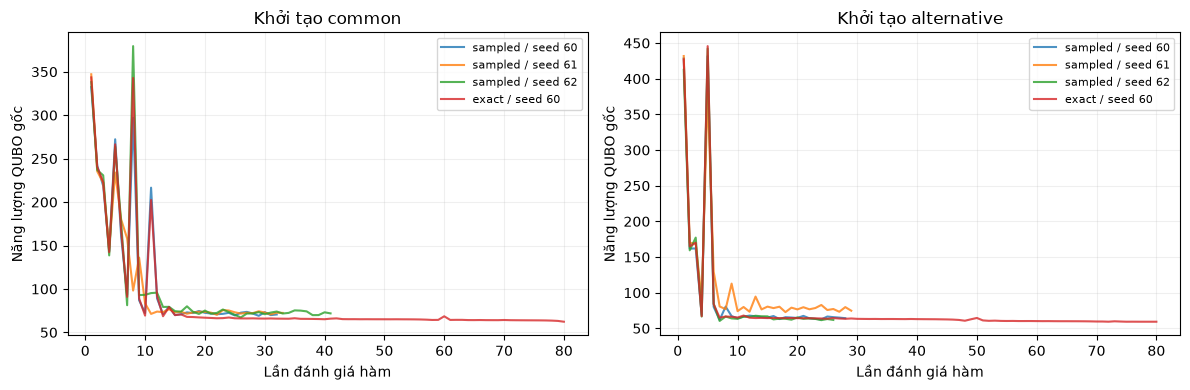

,arm,seed,angle_distance,observed_energy_change,exact_energy_change,SE_at_second_point
0,sampled_common,60,0.000149,0.703125,0.007647,2.140024
1,sampled_common,61,0.000150,-0.286133,0.007408,2.240711
2,sampled_common,62,0.000149,-1.232422,-0.004764,2.218862
3,exact_common,60,0.080000,-0.925557,-0.925557,1.671736
4,sampled_alternative,60,0.000145,-0.785156,0.004847,1.800096
5,sampled_alternative,61,0.000190,-5.032227,0.012599,2.444839
6,sampled_alternative,62,0.000182,-1.300781,0.003092,1.773939
7,exact_alternative,60,0.002550,0.001014,0.001014,1.538965


Thời gian audit thêm: 1.10s


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
tail_rows = []
audit_started = perf_counter()
for row in rows:
    r = json.loads((ROOT / row["report"]).read_text(encoding="utf-8"))
    hist = r["optimization_history"]
    ax = axes[0 if row["initial_point_id"] == "common" else 1]
    ax.plot([h["evaluation"] for h in hist], [h["estimated_qubo_energy"] for h in hist],
            label=f"{row['objective_mode']} / seed {row['seed']}", alpha=.8)
    left, right = hist[-2:]
    a, b = oracle.evaluate(left["parameters"]), oracle.evaluate(right["parameters"])
    tail_rows.append(dict(arm=row["arm_id"], seed=row["seed"],
        angle_distance=float(np.linalg.norm(np.array(right["parameters"])-left["parameters"])),
        observed_energy_change=right["estimated_qubo_energy"]-left["estimated_qubo_energy"],
        exact_energy_change=b["exact_mean_qubo_energy"]-a["exact_mean_qubo_energy"],
        SE_at_second_point=b["standard_error_at_training_shots"]))
for ax, init_id in zip(axes, ("common", "alternative")):
    ax.set(title=f"Khởi tạo {init_id}", xlabel="Lần đánh giá hàm", ylabel="Năng lượng QUBO gốc")
    ax.grid(alpha=.2); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()
campaign["tail_diagnostics"] = tail_rows
campaign["tail_audit_seconds"] = perf_counter() - audit_started
save_campaign(MANIFEST_PATH, campaign)
display(pd.DataFrame(tail_rows).round(8))
print(f"Thời gian audit thêm: {campaign['tail_audit_seconds']:.2f}s")

## Bước 10 — Xác nhận hoàn tất và lưu để review

Hoàn tất đợt này nghĩa là đủ 8 lượt có nguồn dữ liệu đúng, không yêu cầu đủ 80 lần đánh giá và không yêu cầu mọi lượt có nghiệm.

Lưu notebook có output thành `12_qaoa_convergence_diagnostics_choice.ipynb`. Restart kernel, mở notebook gốc, đổi `INSTANCE_ID="p0_reference"` và để `RESUME_MANIFEST=None`; chạy lại Bước 1–10 rồi lưu thành `12_qaoa_convergence_diagnostics_reference.ipynb`.

Để review cả hai input, cung cấp hai notebook có output, hai manifest `convergence_*.json` và 16 report nguồn được các manifest liệt kê. Giữ các kết quả notebook 11 làm mốc lịch sử. B/C có thể tiếp tục baseline/báo cáo trong lúc A chạy chẩn đoán này.

Hướng đọc sau khi có số liệu: exact giảm năng lượng tốt hơn sampled → nhiễu shots có ảnh hưởng; hai khởi tạo exact cho kết quả khác → có ảnh hưởng khởi tạo/cực tiểu cục bộ; exact dừng thành công nhưng P_opt thấp → cần xét mục tiêu tối ưu/ansatz, không chỉ tăng maxiter. Một đợt nhỏ không chứng minh nguyên nhân duy nhất.

In [10]:
verified = verify_campaign(ROOT, campaign, design, bundle, reference)
assert len(verified) == campaign["planned_run_count"] == 8
assert campaign["completed_run_count"] == 8 and campaign["remaining_run_keys"] == []
assert all(r["evaluation_seed"] != r["seed"] and r["evaluation_shots"] == BASE_CONFIG["evaluation_shots"] for r in verified)
print(f"PASS — {INSTANCE_ID}: 8/8 completed, remaining 0, independent final sampling verified.")
print("Manifest:", MANIFEST_PATH.relative_to(ROOT).as_posix())
print("Reports:")
for row in verified:
    print(" -", row["report"])
print("Lưu notebook có output trước khi restart kernel/chuyển instance.")

PASS — p1_choice: 8/8 completed, remaining 0, independent final sampling verified.
Manifest: data/reference_results/phase4e_convergence_runs/convergence_p1_choice_20261008T034113505740Z.json
Reports:
 - data/reference_results/phase4e_convergence_runs/p1_choice_sampled_common_seed60_20261008T034240991372Z.json
 - data/reference_results/phase4e_convergence_runs/p1_choice_sampled_common_seed61_20261008T034245418295Z.json
 - data/reference_results/phase4e_convergence_runs/p1_choice_sampled_common_seed62_20261008T034250553204Z.json
 - data/reference_results/phase4e_convergence_runs/p1_choice_exact_common_seed60_20261008T034257726720Z.json
 - data/reference_results/phase4e_convergence_runs/p1_choice_sampled_alternative_seed60_20261008T034304769989Z.json
 - data/reference_results/phase4e_convergence_runs/p1_choice_sampled_alternative_seed61_20261008T034311831490Z.json
 - data/reference_results/phase4e_convergence_runs/p1_choice_sampled_alternative_seed62_20261008T034318185044Z.json
 - data/re